# 02 · QC and trimming: the decisions
**Goal:** check the raw reads, decide how to trim them, and show the evidence. **Input:** the FastQC reports from Euler (unpacked in notebook 01) and, for the adapter check, one `.sra` file. **Output:** none; this notebook records decisions. **Kernel:** Python 3 · **Time:** minutes.

Per run on Euler: `.sra` → FASTQ → **FastQC** (raw reads) → **fastp** trimming → kallisto, STAR, RSEM (notebook 01; [docs/pipeline.md](../docs/pipeline.md)). Terms: [docs/glossary.md](../docs/glossary.md).

In [1]:
# helpers.py: pipeline functions; runs = sample table
import sys; sys.path.insert(0, '../scripts')
import helpers as h
import pandas as pd
from IPython.display import display
runs = h.load_runs()

## 1 · Quality control of all reads
FastQC runs on **all** reads of every run (the `qc` stage on Euler). Its verdicts come from fixed thresholds (`limits.txt`); some WARNs are normal for RNA-seq.

| Check | WARN when | FAIL when | Expected |
|---|---|---|---|
| Per base sequence quality | lower quartile < 10 or median < 25 | < 5 / < 20 | PASS |
| Per sequence quality scores | most common mean quality < 27 | < 20 | PASS |
| **Adapter Content** | > 5 % of reads | > 10 % | PASS, else trim |
| Overrepresented sequences | one sequence > 0.1 % of reads | > 1 % | WARN common (Smart-seq2 primers) |
| Sequence Duplication Levels | < 70 % of reads remain after dedup | < 50 % | WARN normal (highly expressed genes) |

**Result:** base quality PASS in all 54 read files; **adapter content FAIL in all 54** (17–34 % of reads run into Nextera transposase sequence, because fragments are shorter than the 150-base read); overrepresented sequences and duplication WARN, as expected.

In [2]:
# FastQC verdicts of every read file (from the reports unpacked in notebook 01)
h.fastqc_summary(list(runs.index))

,Per base sequence quality,Per sequence quality scores,Adapter Content,Overrepresented sequences,Sequence Duplication Levels
SRR21355401_1,PASS,PASS,FAIL,WARN,WARN
SRR21355401_2,PASS,PASS,FAIL,WARN,WARN
SRR21355396_1,PASS,PASS,FAIL,WARN,WARN
SRR21355396_2,PASS,PASS,FAIL,WARN,WARN
SRR21355392_1,PASS,PASS,FAIL,WARN,WARN
SRR21355392_2,PASS,PASS,FAIL,WARN,WARN
SRR21355388_1,PASS,PASS,FAIL,WARN,WARN
SRR21355388_2,PASS,PASS,FAIL,WARN,WARN
SRR21355398_1,PASS,PASS,FAIL,WARN,WARN
SRR21355398_2,PASS,PASS,FAIL,WARN,WARN


In [3]:
# the numbers behind the verdicts: min / median / max over the 54 read files (Phred scores; % of reads)
raw = h.fastqc_metrics(list(runs.index))
raw.agg(['min', 'median', 'max']).T.round(2)

,min,median,max
base_median_min,37.00,37.00,37.00
base_lowerq_min,25.00,37.00,37.00
base_mean_min,31.48,32.61,33.24
seq_mean_q,36.00,36.00,36.00
nextera_max,16.80,26.18,33.53
polyA_max,2.27,3.00,3.86
polyG_max,3.10,4.79,9.48
overrep_top,0.11,0.19,0.38
dedup_pct,53.80,64.25,68.70


## 2 · Trim or not?
Adapters fail in **every** sample, so **all** runs are trimmed with the same settings (trimming only some would create a technical difference between groups). fastp detects the adapter from the read pair, trims poly-G tails, keeps reads ≥ 20 bases and drops low-quality reads (about 4–6 % of pairs). Duplicates are **not** removed (see glossary).

**Effect of trimming** (early test on five runs first quantified untrimmed, vM25 reference): the pseudoaligned share rose by 2.1–2.7 points.

### Check: adapter and poly-G (SRR21355398, first 600,000 read pairs)
**Is it the adapter?** Yes.
- The 12 bases `CTGTCTCTTATA` start the Nextera adapter (expected for a Tn5 library) and occur in 27–30 % of reads, vs ≈ 5 expected by chance.
- The bases after them match the read's *own* mate's adapter in 96–99 % of cases, the other mate's in 0 %.
- After trimming, FastQC's Nextera adapter content drops from 27–29 % to 0.05 % (SRR21355398, first 600,000 pairs, FastQC 0.13).

**Poly-G** (a tail of ≥ 10 G at the read end, the rule fastp's `--trim_poly_g` uses): the NovaSeq reads a cluster with no light as G. After a short insert a read runs through the adapter, a sample barcode and more library construct, then out of template; the remaining cycles are dark:
```
read    [ insert ][ adapter ][ barcode ][ rest of construct ][ no template left: dark -> GGGGGGG ]
bases      ~50         34          8            ~34                  ~23      (medians, mate 1, SRR21355398)
```
Medians of the mate-1 reads with a poly-G tail of one run (SRR21355398, first 600,000 pairs; measured below). The adapter (34) and barcode (8) have fixed lengths; the construct is what remains between the barcode and the G tail. The insert and the tail vary from read to read, and other runs were not measured.
Only 4.5–6.5 % of reads have a poly-G tail (27–30 % reach the adapter), and 81–92 % of those lie behind the adapter. The G's have high quality (mean Q31–32 against Q33 for all bases), so quality trimming misses them. Adapter cutting alone removes the tail in 95 % of these reads, fastp's filters drop 3–4 %, and 0.8–2.2 % keep it. `--trim_poly_g` catches the rest, so **it is on for all 27 runs**. Without it (one run tested) pseudoalignment was identical (65.20 %) and counts changed by 0.05 %, but a few G-rich genes (Gm19220, Gm26822, Grip2) were inflated by residual poly-G reads (`results/qc/polyG_sensitivity_SRR21355398.csv`); none is differentially expressed.

In [4]:
# where the parts of a poly-G read lie: median [middle half] in bases, mate 1 and mate 2 (needs the .sra; ~1 min)
if h.has_sra('SRR21355398'):
    display(h.tail_anatomy('SRR21355398'))

,reads,adapter_length,insert,adapter_to_tail,G_tail,barcode_share_%
mate 1,31455,34,50 [42-58],76 [75-77],23 [16-31],87
mate 2,24696,33,46 [39-52],80 [79-86],21 [15-28],96


In [5]:
# per mate: adapter evidence and the fate of poly-G reads (needs the .sra on this machine; re-runs fastq-dump and fastp on 600k pairs, ~1 min)
if h.has_sra('SRR21355398'):
    display(h.adapter_check('SRR21355398').T)
else:
    print('SRR21355398.sra is not on this machine: h.download_run(\'SRR21355398\') fetches it (needs sra-tools); the results are described in the text above')

mate,1,2
reads,600000.0,600000.0
adapter_start_%,27.2,29.6
expected_by_chance_reads,5.0,5.0
continues_own_adapter_%,95.8,98.5
matches_other_mate_adapter_%,0.0,0.0
polyG_reads_%,6.5,4.5
polyG_after_adapter_%,80.7,91.5
polyG_dropped_%,4.4,3.1
polyG_removed_%,94.8,94.7
polyG_remaining_%,0.8,2.2


### Check: poly-A and poly-G tails, before and after trimming
Poly-G (above) is trimmed. Poly-A (or poly-T, the same on the other strand) is **not**: the library is built from poly-A mRNA, so some reads contain A-runs, but they are rare, and a poly-A tail is not part of the annotated transcript, so it does not match and is ignored or soft-clipped. fastp's `--trim_poly_x` could remove them; we did not use it. Share of reads (first 600,000 pairs of SRR21355398); `ends_in_G` should be ~0 after trimming:

In [6]:
# poly-A / poly-T runs (>= 12), reads ending in poly-A or poly-G, before and after fastp (needs the .sra; ~1 min)
if h.has_sra('SRR21355398'):
    display(h.tail_check('SRR21355398'))

,reads,A_run,T_run,ends_in_A,starts_with_T,ends_in_G
raw mate 1,600000.0,2.60,3.33,0.39,0.03,6.5
raw mate 2,600000.0,2.89,3.17,0.44,0.03,4.5
trimmed mate 1,562779.0,1.15,1.85,0.21,0.02,0.0
trimmed mate 2,562779.0,1.45,1.29,0.27,0.01,0.0


## 3 · QC after trimming (all runs)
FastQC on the **trimmed** reads (the `qctrim` stage on Euler, made with the identical fastp command; copied back by notebook 01). Expected: adapter content (Nextera) falls below 1 %, the adapter and quality verdicts PASS, and the overrepresented-sequence WARN stays (those are library primers, which trimming does not remove). Duplication is not removed, so it does not change; note that FastQC's duplication estimate depends on file size, so compare raw and trimmed only for the same run.

In [7]:
# FastQC verdicts of the trimmed reads (empty until the trimmed reports are unpacked)
h.fastqc_summary(list(runs.index), which='trimmed')

,Per base sequence quality,Per sequence quality scores,Adapter Content,Overrepresented sequences,Sequence Duplication Levels
SRR21355401_1,PASS,PASS,PASS,WARN,WARN
SRR21355401_2,PASS,PASS,PASS,WARN,WARN
SRR21355396_1,PASS,PASS,PASS,WARN,WARN
SRR21355396_2,PASS,PASS,PASS,WARN,WARN
SRR21355392_1,PASS,PASS,PASS,WARN,WARN
SRR21355392_2,PASS,PASS,PASS,WARN,WARN
SRR21355388_1,PASS,PASS,PASS,WARN,WARN
SRR21355388_2,PASS,PASS,PASS,WARN,WARN
SRR21355398_1,PASS,PASS,PASS,WARN,WARN
SRR21355398_2,PASS,PASS,PASS,WARN,WARN


In [8]:
# raw vs trimmed: min / median / max over the read files
trim = h.fastqc_metrics(list(runs.index), which='trimmed')
if len(trim):
    display(pd.concat({'raw': raw.agg(['min', 'median', 'max']).T, 'trimmed': trim.agg(['min', 'median', 'max']).T}, axis=1).round(2))

raw               trimmed              
                   min median    max     min median    max
base_median_min  37.00  37.00  37.00   37.00  37.00  37.00
base_lowerq_min  25.00  37.00  37.00   37.00  37.00  37.00
base_mean_min    31.48  32.61  33.24   32.55  33.83  34.46
seq_mean_q       36.00  36.00  36.00   36.00  36.00  36.00
nextera_max      16.80  26.18  33.53    0.01   0.03   0.05
polyA_max         2.27   3.00   3.86    1.22   1.63   2.06
polyG_max         3.10   4.79   9.48    0.03   0.05   0.06
overrep_top       0.11   0.19   0.38    0.00   0.11   0.38
dedup_pct        53.80  64.25  68.70   53.40  64.50  68.90

### Slide figure
The essential result of the trimming: adapter content before and after (one dot per read file, 54 files). Saved as `results/qc/adapter_content_before_after.png` (300 dpi) and `.svg`.

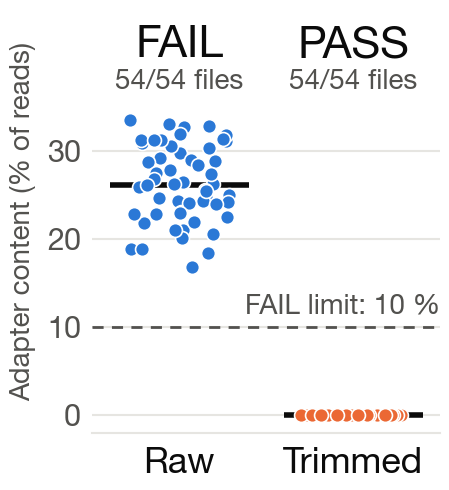

In [9]:
fig = h.plot_adapter_effect(raw, trim, h.QC / 'adapter_content_before_after')